<a href="https://colab.research.google.com/github/wellickdev/python/blob/main/lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
N = ord("P") % 3 + 1
N

3

# Лабораторна робота №4. Дослідження та візуалізація даних за допомогою Python
# Мета роботи: Отримати базові навики використання Python для дослідження та візуалізації даних

## Завдання 1: Створіть функцію, яка приймає назву файлу та назву стовпця як параметр та повертає масив numpy зі значеннями стовпця.



In [13]:
import csv
import numpy as np
import matplotlib.pyplot as plt


def get_column(filename, column_name):
    """
    Зчитує CSV-файл за допомогою csv.reader(), пропускає рядок заголовків
    і повертає масив numpy зі значеннями вказаного стовпця.
    """
    with open(filename, mode='r', encoding='utf-8') as file:
        reader = csv.reader(file)
        header = next(reader)  # зчитуємо і пропускаємо перший рядок із заголовками
        col_idx = header.index(column_name)
        data = np.array(list(reader))

    col = data[:, col_idx]

    # Якщо стовпець числовий — перетворюємо на int, якщо текстовий (напр. 'date') — залишаємо рядками
    try:
        col_clean = np.where(col == '', '0', col)
        return col_clean.astype(float).astype(int)
    except ValueError:
        return col

## Завдання 2: Використовуючи функцію з попереднього завдання, створіть масив numpy зі значень стовпця «APC» (Armored personnel carrier).

In [14]:
filename = 'russia_losses_equipment.csv'

apc = get_column(filename, 'APC')
dates = get_column(filename, 'date').astype('datetime64[D]')
days = get_column(filename, 'day')

# Впорядковуємо масиви хронологічно (від першого дня війни до останнього в наборі)
order = np.argsort(dates)
dates = dates[order]
days = days[order]
apc = apc[order]

## Завдання 3: Знайдіть добові втрати БТР.

In [15]:
def get_daily_losses(cumulative_losses):
    """Повертає масив добових втрат як різницю між сусідніми днями."""
    return np.diff(cumulative_losses)

daily_apc = get_daily_losses(apc)

# Оскільки np.diff() зменшує довжину масиву на 1 (різниця починається з 2-го запису),
# беремо відповідні зрізи дат і номерів днів
dates_daily = dates[1:]
days_daily = days[1:]

print("Добові втрати БТР (перші 10 днів):", daily_apc[:10])
print("Добові втрати БТР (останні 10 днів):", daily_apc[-10:])

Добові втрати БТР (перші 10 днів): [190   0 110  30  16  38  39   6  40  14]
Добові втрати БТР (останні 10 днів): [14 11 19 34 23  6  2 13 32 24]


## Завдання 4: Знайдіть 5 найбільших добових втрат БТР.

In [16]:
def get_top_daily_losses(daily_losses, dates_arr, n=5):
    """Знаходить n найбільших добових втрат та відповідні їм дати."""
    top_indices = np.argsort(daily_losses)[-n:][::-1]
    return daily_losses[top_indices], dates_arr[top_indices]

top_5_losses, top_5_dates = get_top_daily_losses(daily_apc, dates_daily, n=5)

print("5 найбільших добових втрат БТР:", top_5_losses)
print("Дати цих втрат:                ", top_5_dates)

5 найбільших добових втрат БТР: [190 120 110  96  91]
Дати цих втрат:                 ['2022-02-26' '2023-10-20' '2022-02-28' '2022-03-16' '2023-10-11']


## Завдання 5: Визначте, скільки БТР було знищено влітку 2024 року.

In [17]:
def get_summer_2024_losses(daily_losses, dates_arr):
    """Обчислює сумарні втрати БТР за літо 2024 року (01.06.2024 – 31.08.2024)."""
    mask = (dates_arr >= np.datetime64('2024-06-01')) & (dates_arr <= np.datetime64('2024-08-31'))
    return int(np.sum(daily_losses[mask]))

summer_2024_apc = get_summer_2024_losses(daily_apc, dates_daily)
print(f"Кількість БТР, знищених влітку 2024 року: {summer_2024_apc}")

Кількість БТР, знищених влітку 2024 року: 1801


## Завдання 6: Знайдіть середнє значення знищених БТР за 100-500 днів війни.


In [18]:
def get_mean_losses_for_days(daily_losses, days_arr, start_day=100, end_day=500):
    """Знаходить середнє значення добових втрат БТР за вказаний проміжок днів війни."""
    mask = (days_arr >= start_day) & (days_arr <= end_day)
    return float(np.mean(daily_losses[mask]))

mean_100_500 = get_mean_losses_for_days(daily_apc, days_daily, 100, 500)
print(f"Середнє значення знищених БТР за 100-500 дні війни: {mean_100_500:.2f} од./добу")

Середнє значення знищених БТР за 100-500 дні війни: 11.47 од./добу


## Завдання 7: Створіть графік втрат БТР за останні 200 днів (починаючи з останньої дати в наборі даних)


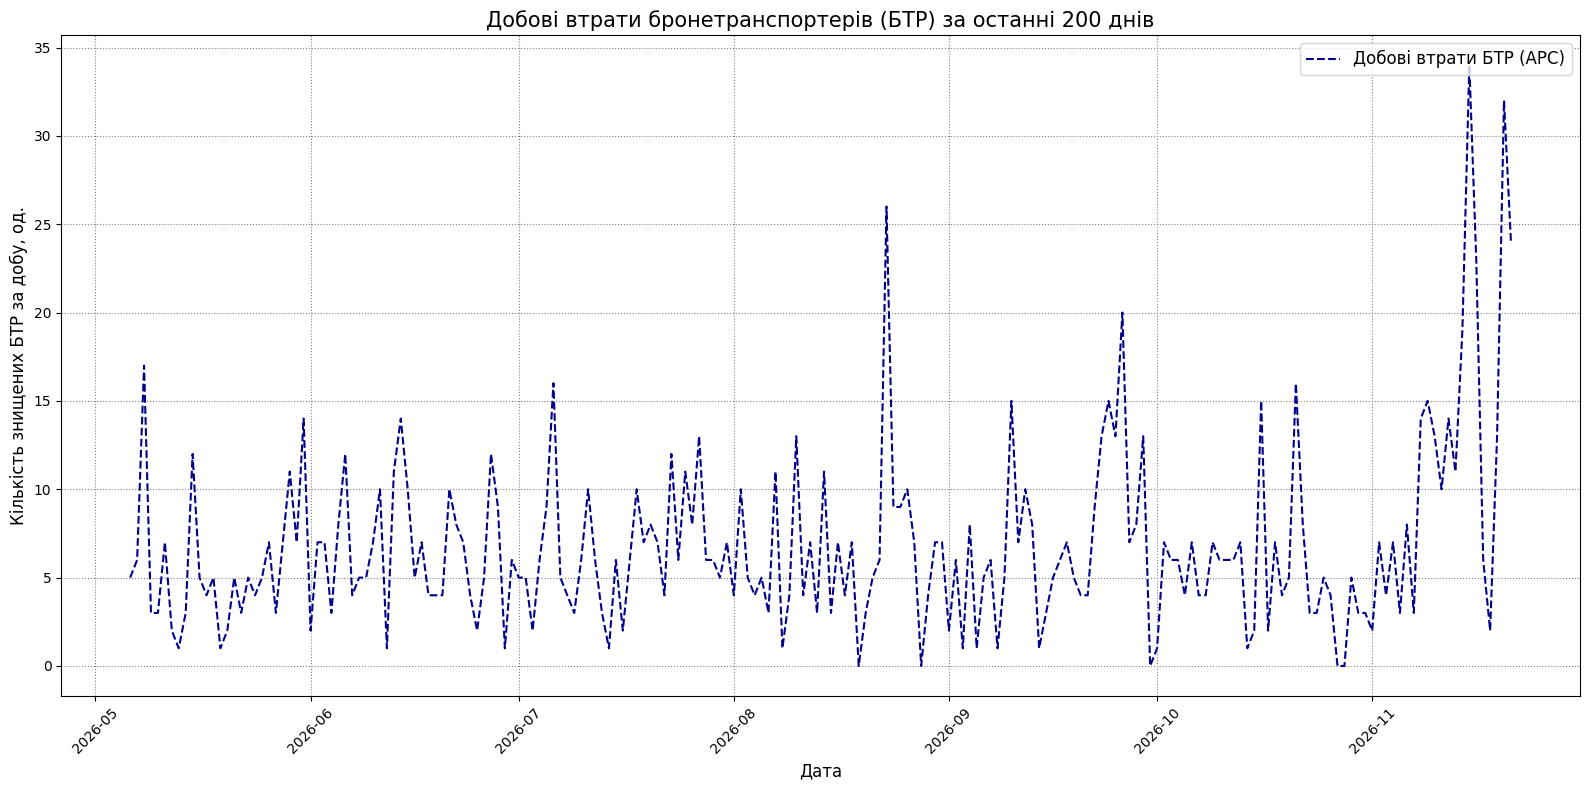

In [19]:
def plot_last_n_days_losses(daily_losses, dates_arr, n=200, save_path='apc_losses_last_200_days.png'):
    """Будує та зберігає графік добових втрат БТР за останні n днів."""
    last_dates = dates_arr[-n:]
    last_losses = daily_losses[-n:]

    # f. розмір графіка та роздільна здатність
    plt.figure(figsize=(16, 8), dpi=100)

    # a, b. тип лінії (пунктирна '--') та підпис графіка (label)
    plt.plot(
        last_dates,
        last_losses,
        linestyle='--',
        color='darkblue',
        linewidth=1.5,
        label='Добові втрати БТР (APC)'
    )

    # e. назва графіка, позначки осей і читабельні значення на осях
    plt.title(f'Добові втрати бронетранспортерів (БТР) за останні {n} днів', fontsize=15)
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Кількість знищених БТР за добу, од.', fontsize=12)
    plt.xticks(rotation=45)

    # d. сітка із зазначенням кольору та типу ліній
    plt.grid(True, color='gray', linestyle=':', linewidth=0.8)

    # c. легенда
    plt.legend(fontsize=12, loc='upper right')

    plt.tight_layout()

    # g. збереження у файл формату png (обов'язково ДО plt.show())
    plt.savefig(save_path, dpi=100)
    plt.show()

plot_last_n_days_losses(daily_apc, dates_daily, n=200)